In [3]:
import pandas as pd

df = pd.read_csv(
    '/content/Indic_Climate_Stance_Expanded_1806_FIXED.csv',
    keep_default_na=False
)

print("Dataset Shape:", df.shape)

print("\nStance Label Distribution:")
print(df['stance_label'].value_counts())

print("\nLanguage Distribution:")
print(df['detected_language'].value_counts())

Dataset Shape: (1806, 13)

Stance Label Distribution:
stance_label
Favour     650
Against    598
None       332
           226
Name: count, dtype: int64

Language Distribution:
detected_language
hi       520
bn       487
hi-en    439
bn-en    359
en         1
Name: count, dtype: int64


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nFirst 10 Dataset Records:")
display(df[['text', 'detected_language', 'stance_label', 'data_origin']].head(10))

Column Names:
['record_id', 'comment_id', 'synthetic_id', 'video_id', 'text', 'detected_language', 'stance_label', 'confidence', 'data_origin', 'parent_seed_id', 'source_platform', 'annotator_id', 'annotation_confidence']

First 10 Dataset Records:


,text,detected_language,stance_label,data_origin
0,জলবায়ু পরিবর্তন মানব সৃষ্ট মানুষ দিন দিন যত আ...,bn,Favour,Real
1,प्रलय आएगा जरूर क्योंकि लोग जंगल काट रहे हैं झ...,hi,,Real
2,Eto manuser jonno hocche.,bn,,Real
3,आप के विश्लेषण से मैं सहमत हूं। क्यों कि मैं भ...,hi,Favour,Real
4,"ग्लोबल वार्मिंग का में कारण ओवर पॉपुलेशन है,एक...",hi,,Real
5,Kicu korar nai,bn,,Real
6,फिर भी दिन व दिन जंगल समाप्त हो रहा है पहाड़ त...,hi,,Real
7,Tap matra barche volcanor kacher prae 100 km d...,bn-en,Favour,Real
8,क्या आपको पता है जलवायु परिवर्तन का एक मुख्य क...,hi,Favour,Real
9,जलवायु परिवर्तन आने वाले समय मे भारत में खाद्य...,hi,Favour,Real


In [5]:
print("Data Origin Distribution:")
print(df['data_origin'].value_counts())

print("\nStance labels by Data Origin:")
print(pd.crosstab(df['data_origin'], df['stance_label']))

print("\nMissing labels:")
print((df['stance_label'].str.strip() == '').sum())

Data Origin Distribution:
data_origin
Synthetic    1728
Real           78
Name: count, dtype: int64

Stance labels by Data Origin:
stance_label       Against  Favour  None
data_origin                             
Real           46        2      30     0
Synthetic     180      596     620   332

Missing labels:
226


In [6]:
# Remove extra spaces from labels
df['stance_label'] = df['stance_label'].str.strip()

# Keep only records with valid stance labels
labelled_df = df[
    df['stance_label'].isin(['Favour', 'Against', 'None'])
].copy()

print("Total labelled records:", len(labelled_df))

print("\nFinal class distribution:")
print(labelled_df['stance_label'].value_counts())

print("\nRecords by origin:")
print(labelled_df['data_origin'].value_counts())

Total labelled records: 1580

Final class distribution:
stance_label
Favour     650
Against    598
None       332
Name: count, dtype: int64

Records by origin:
data_origin
Synthetic    1548
Real           32
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Remove records with empty text
labelled_df = labelled_df[
    labelled_df['text'].str.strip() != ''
].copy()

X = labelled_df['text']
y = labelled_df['stance_label']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Build TF-IDF + Linear SVM model
model = Pipeline([
    ('features', FeatureUnion([
        ('word_tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ('char_tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(3, 5),
            sublinear_tf=True
        ))
    ])),
    ('classifier', LinearSVC(class_weight='balanced'))
])

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

print("Training completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Macro F1-Score:", f1_score(y_test, y_pred, average='macro'))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Training completed!
Training samples: 1264
Testing samples: 316

Accuracy: 0.9936708860759493
Macro F1-Score: 0.9946581196581197

Classification Report:
              precision    recall  f1-score   support

     Against       0.99      0.99      0.99       120
      Favour       0.99      0.99      0.99       130
        None       1.00      1.00      1.00        66

    accuracy                           0.99       316
   macro avg       0.99      0.99      0.99       316
weighted avg       0.99      0.99      0.99       316



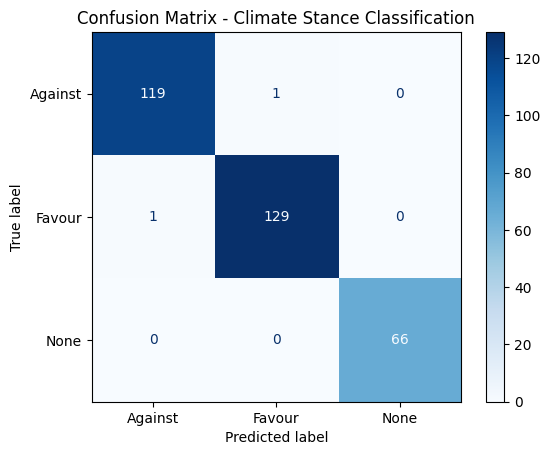

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Against', 'Favour', 'None']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Against', 'Favour', 'None']
)

display.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Climate Stance Classification")
plt.show()

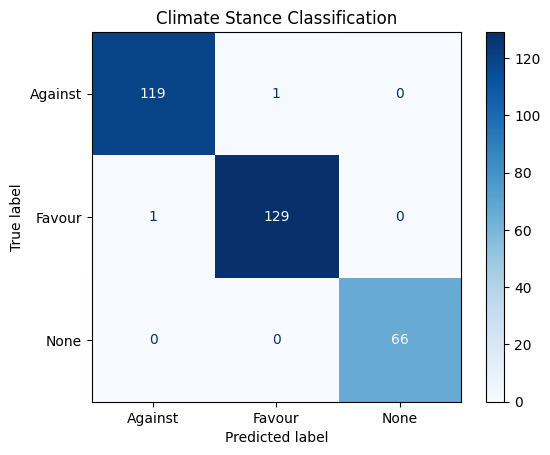

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Against', 'Favour', 'None']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Against', 'Favour', 'None']
)

display.plot(cmap='Blues', values_format='d')
plt.title("Climate Stance Classification")
plt.show()

In [10]:
test_results = labelled_df.loc[X_test.index, ['data_origin', 'stance_label']].copy()

print("Test set: Real vs Synthetic")
print(test_results['data_origin'].value_counts())

print("\nClass distribution by origin:")
print(pd.crosstab(
    test_results['data_origin'],
    test_results['stance_label']
))

Test set: Real vs Synthetic
data_origin
Synthetic    307
Real           9
Name: count, dtype: int64

Class distribution by origin:
stance_label  Against  Favour  None
data_origin                        
Real                1       8     0
Synthetic         119     122    66


In [11]:
import joblib

joblib.dump(model, 'climate_stance_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [12]:
from google.colab import files

files.download('climate_stance_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>